In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

print(Path.cwd())

from nix2_mc import LatticeNiX2, SpinModelNiX2, MonteCarloNiX2
from nix2_mc_output import create_run_folder, save_temperature_results

d:\GitHub_REPOSITORY\Spin_Models_REPO\NiX2_SPINS


In [2]:
from nix2_model_builders import *

In [3]:
Lmuc = 7
Nmuc = 4
Na = Nmuc * Lmuc
Nb = 2 * Na
geometry = "rectangular"

nix2_lattice = build_nix2_lattice(Na, Nb, geometry=geometry)

In [4]:
# parameters
Azz = 0.140
J1prime = -4.976
Kitaev = 0.858
B_biquad = -0.719
J2iso = -0.155
J3iso = 2.250

# tensors
J1mat = exchange_from_hk(J1prime, Kitaev)
J2mat = J2iso * np.eye(3)
J3mat = J3iso * np.eye(3)

model_params = {
    "J1": J1mat,
    "J2": J2iso,
    "J3": J3iso,
    "Azz": Azz,
    "B_biquad": B_biquad,
    "zeeman": (0.0, 0.0, 0.0)
}

# build model
nix2_model = build_nix2_model(J1mat, J3=J3iso, J2iso=J2iso, 
                              Azz=Azz, B_biquad=B_biquad, B_field=(0.0, 0.0, 0.0), 
                              geometry="rectangular")

In [5]:
print("ratio of J3 to J_1^{\prime} : ", J3iso / J1prime)
print("ratio of B to J_1^{\prime} : ", B_biquad / J1prime)

ratio of J3 to J_1^{\prime} :  -0.4521704180064309
ratio of B to J_1^{\prime} :  0.14449356913183278


In [6]:
import secrets

seed = secrets.randbits(128)
current_rng = np.random.default_rng(seed=seed)
nix2_mc = MonteCarloNiX2(lattice=nix2_lattice, spin_model=nix2_model, seed=seed)

In [7]:
# Plotting helpers and common appearance.
from plotting_3d_spins import (
    PLOT_CONFIG, plot_spin_config, plot_spin_texture, plot_spin_angles, plot_curves,
)
plt.rcParams.update(PLOT_CONFIG)

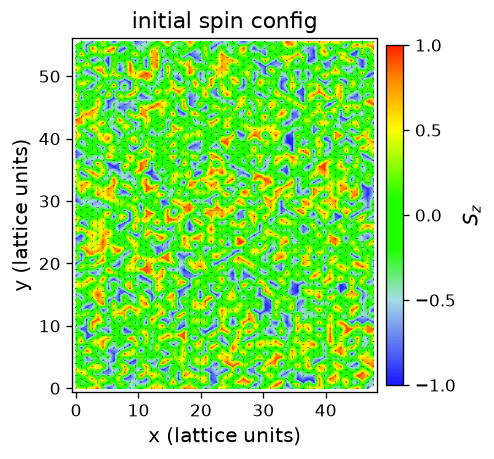

In [8]:
# Current spin configuration: Sz background and in-plane spin arrows.
ax = plot_spin_texture(
    nix2_mc.spin_config, nix2_mc.lat,
    title="initial spin config", figsize=(4, 4),
)
plt.show()

### temperatures from HIGH to LOW for annealing
I have checked the validity of this annealing in another notebook

In [9]:
from nix2_mc_protocols import *

In [10]:
# temperatures
TK_init_list = [70, 50, 20]
TK_final_list = [50, 20, 1]
cooling_method_list = ["linear", "linear", "linear"]
cooling_rate_list = [20, 30, 19]

TK_list = set_temperature_schedule(
    TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list,
)

In [11]:
measurements = make_measurements(
    nix2_mc,
    observables=["energy", "magnetization"],
)

In [12]:
num_eq_sweeps = 15000
converg_per_every = 10
num_meas_sweeps = 10000
meas_per_every = 5

In [13]:
mc_parameters={
    # lattice parameters
    "Nx": Na,
    "Ny": Nb,
    "Ns": 2,
    "geometry": "rectangular",
    
    # model parameters
    "model_params": model_params,

    # Monte Carlo parameters
    "seed": seed,
    "num_eq_sweeps": num_eq_sweeps, 
    "converg_per_every": converg_per_every,
    "num_meas_sweeps": num_meas_sweeps, 
    "meas_per_every": meas_per_every,
    "temperatures_info":(TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list),
    "reset_probability": 0.02,
}

current_folder = create_run_folder(root="nix2_simulation_results", parameters=mc_parameters,
                                    prefix="NiX2_annealing_")

### MC Simulation Starts

In [14]:
from nix2_mc_protocols import run_mc_annealing

results = run_mc_annealing(
    nix2_mc, TK_list, current_folder,
    num_eq_sweeps=num_eq_sweeps,
    num_meas_sweeps=num_meas_sweeps,
    converg_per_every=converg_per_every,
    meas_per_every=meas_per_every,
    observables=["energy"]
)

T = 70.00 K, E = -15294.683278 meV
T = 68.95 K, E = -15829.971171 meV
T = 67.89 K, E = -16347.562144 meV
T = 66.84 K, E = -16706.067062 meV
T = 65.79 K, E = -15887.414179 meV
T = 64.74 K, E = -16483.842613 meV
T = 63.68 K, E = -16415.376958 meV
T = 62.63 K, E = -16956.556233 meV
T = 61.58 K, E = -17089.438241 meV
T = 60.53 K, E = -17524.957181 meV
T = 59.47 K, E = -16883.397765 meV
T = 58.42 K, E = -17819.949517 meV
T = 57.37 K, E = -17551.079560 meV
T = 56.32 K, E = -18083.410993 meV
T = 55.26 K, E = -17751.363621 meV
T = 54.21 K, E = -18436.991295 meV
T = 53.16 K, E = -18414.563104 meV
T = 52.11 K, E = -18817.809086 meV
T = 51.05 K, E = -19049.403155 meV
T = 50.00 K, E = -19181.547997 meV
T = 50.00 K, E = -19208.303720 meV
T = 48.97 K, E = -19254.270202 meV
T = 47.93 K, E = -19646.833751 meV
T = 46.90 K, E = -20123.800151 meV
T = 45.86 K, E = -20074.362997 meV
T = 44.83 K, E = -20208.302723 meV
T = 43.79 K, E = -20634.852044 meV
T = 42.76 K, E = -21061.099547 meV
T = 41.72 K, E = -21

In [ ]:
measured_temperatures_K = results["temperatures_K"]
neel_norm_of_mean_list = results["samples"]
neel_samples_by_temperature = results["neel_samples_by_temperature"]
neel_squared_temperature_list = results["neel_squared_temperature_list"]

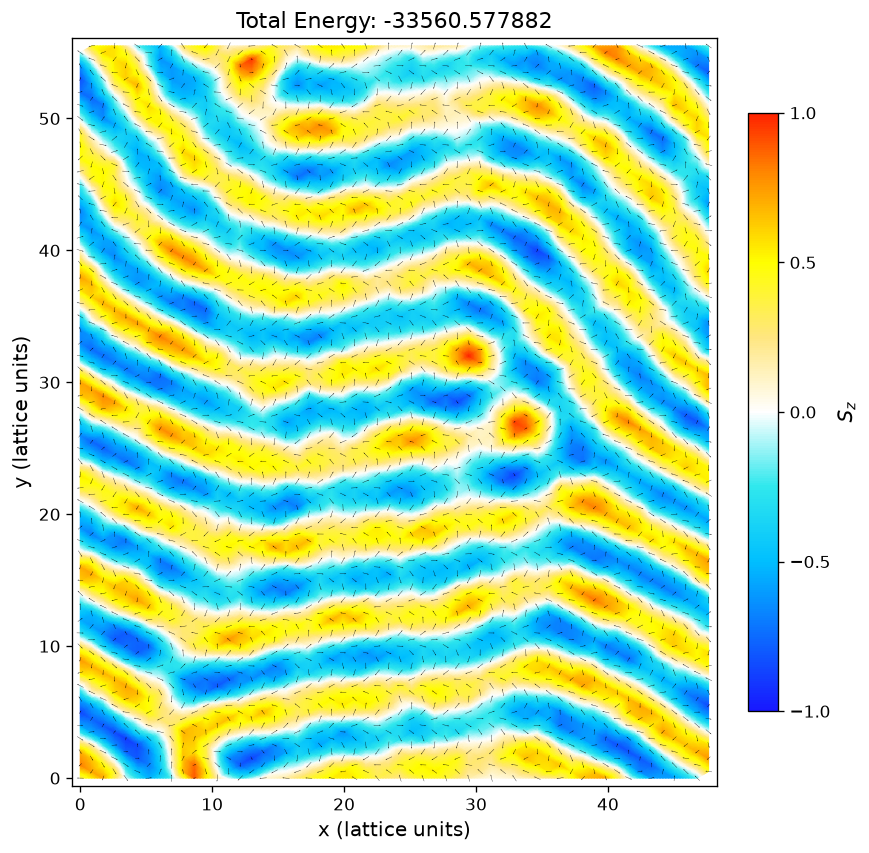

<Axes: title={'center': 'Total Energy: -33560.577882'}, xlabel='x (lattice units)', ylabel='y (lattice units)'>

In [15]:
plot_spin_config(
    nix2_mc.spin_config,
    nix2_mc.lat,
    title=f"Total Energy: {nix2_mc.total_energy():.6f}",
    figsize=(10, 7),
)